# 03 — Match simulated digits by geometry

Fit the picked particles from notebook 02 to the designs saved by notebook 00, allowing translation and in-plane rotation.

The current **6 and 9 have identical geometry after a 180° rotation**. Those fits remain ambiguous instead of receiving a forced digit label.

## 1. Load picks and choose parameters

Use the same picking method/run as notebook 02. Distances are camera pixels; template spacing comes from the saved simulation metadata. Start with `run_full=False` for six particles, or keep `True` for the current 30-particle field.

In [1]:
%matplotlib inline
from pathlib import Path
from time import perf_counter
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from picasso import io

project_dir = Path.cwd().resolve()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))
from src.geometry_matching import load_designs, match_particle

input_dir = project_dir / "data/derived/digits/full_01/picasso_addon"
run_full, preview_count = True, 6  # False: a small preview; True: every saved particle.
run_id, seed = "geometry_01", 7  # Output trial label and reproducible fitting sample.
fit_settings = dict(
    max_fit_locs=2000,  # Maximum detections used in a fit
    angle_step=10, n_starts=8,  # Coarse angle spacing in degrees; refined starting poses.
    max_iter=150,  # Iterations per start; increase if fits do not converge.
    threshold_fraction=0.25,  # Occupied-site threshold relative to the ten brightest sites.
)
acceptance = dict(
    max_hamming=6, min_gap=0.05,  # Allowed occupancy mismatches and minimum class-score gap.
    max_background=0.35, max_rms_pitch=0.8,  # Background fraction and residual / grid spacing.
)

In [2]:
if not (input_dir / "picked_locs.hdf5").is_file():
    raise FileNotFoundError("Run notebook 02 first, or choose its saved picking folder.")
locs, info = io.load_locs(str(input_dir / "picked_locs.hdf5"))
particles = pd.read_csv(input_dir / "particles.csv").set_index("group")
class_ids, patterns, grid = load_designs(info)
radius = next(item["Pick radius (camera pixels)"] for item in reversed(info)
              if "Pick radius (camera pixels)" in item)
groups = particles.index.to_numpy()
if not run_full:
    groups = groups[np.linspace(0, len(groups)-1, min(preview_count, len(groups)), dtype=int)]
if not len(groups):
    raise ValueError("No selected particles. Review the picks in notebook 02.")
group_indices = locs.groupby("group").indices
scope = "full" if run_full else "preview"
print(f"{scope}: {len(groups)}/{len(particles)} particles; {len(class_ids)} input designs.")
print(f"Grid spacing: {np.linalg.norm(grid[1]-grid[0]):.4f} camera pixels; crop radius: {radius:g}.")

full: 30/30 particles; 10 input designs.
Grid spacing: 0.1538 camera pixels; crop radius: 1.2.


## 2. Check the saved designs

These are the supplied patterns, including sites that may be missing from individual simulated particles. Custom class IDs and rectangular layouts are read from metadata

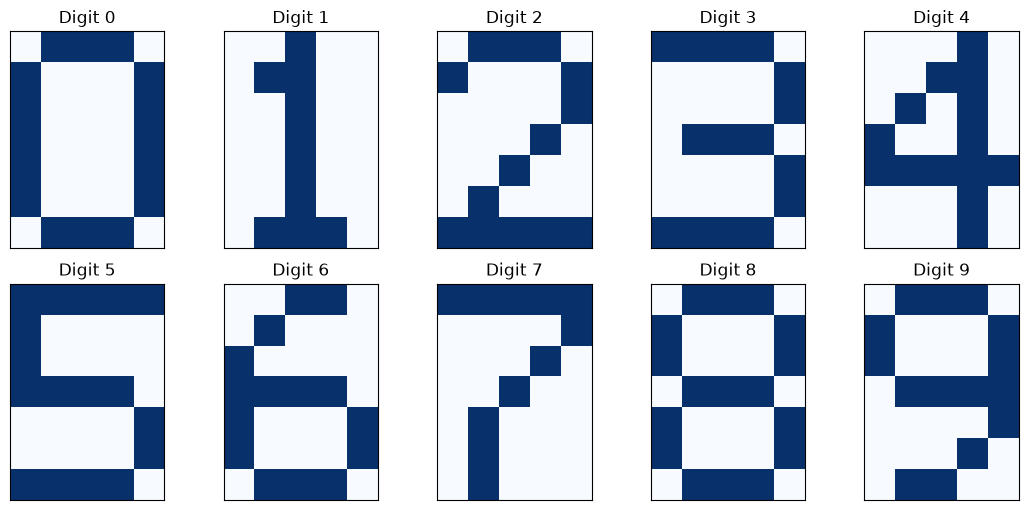

In [3]:
columns = min(5, len(class_ids))
rows = int(np.ceil(len(class_ids)/columns))
fig, axes = plt.subplots(rows, columns, figsize=(2.2*columns, 2.6*rows), squeeze=False)
for digit, pattern, ax in zip(class_ids, patterns, axes.flat):
    ax.imshow(pattern, cmap="Blues", vmin=0, vmax=1, interpolation="nearest")
    ax.set(title=f"Digit {digit}", xticks=[], yticks=[])
for ax in list(axes.flat)[len(class_ids):]:
    ax.set_visible(False)
fig.tight_layout()
plt.show()

## 3. Match the particles

Fit grid position, angle, site brightness and background, then rank the input patterns. `best_digit` is the strongest candidate; `digit_id = -1` means review is needed. `equivalent_digits` lists designs that geometry cannot distinguish. Scores and score gaps are not probabilities.

In [4]:
results, started = {}, perf_counter()
for number, group in enumerate(groups, 1):
    particle = locs.iloc[group_indices[group]]
    center = particles.loc[group, ["x", "y"]].to_numpy(dtype=float)
    results[int(group)] = match_particle(
        particle, patterns, grid, class_ids=class_ids, pick_center=center,
        radius=radius, seed=seed, **fit_settings, **acceptance,
    )
    if number % 10 == 0 or number == len(groups):
        print(f"Fitted {number}/{len(groups)} particles in {perf_counter()-started:.1f} s.")
assignments = pd.DataFrame([dict(group=g, **r["summary"]) for g, r in results.items()])
print(f"Accepted {assignments.accepted.sum()}/{len(assignments)} with provisional criteria.")
assignments[["group", "best_digit", "equivalent_digits", "digit_id", "angle_deg",
             "hamming", "score_gap", "reason"]]

Fitted 10/30 particles in 9.1 s.


Fitted 20/30 particles in 19.5 s.


Fitted 30/30 particles in 27.6 s.
Accepted 21/30 with provisional criteria.


,group,best_digit,equivalent_digits,digit_id,angle_deg,hamming,score_gap,reason
0,0,4,4,4,259.468661,1,6.469860e-01,accepted
1,1,0,0,0,48.173042,0,3.051009e-01,accepted
2,2,6,6/9,-1,23.043173,3,1.110223e-16,ambiguous_class
3,3,1,1,1,357.076355,0,4.188248e-01,accepted
4,4,1,1,-1,302.097421,7,1.026411e-01,too_many_bit_mismatches
5,5,7,7,7,190.783945,2,4.606694e-01,accepted
6,6,5,5,5,80.757609,2,3.890334e-01,accepted
7,7,8,8,8,156.867440,0,2.556866e-01,accepted
8,8,0,0,0,30.095494,0,3.243822e-01,accepted
9,9,8,8,8,129.572088,1,2.913094e-01,accepted


## 4. Inspect the fits

Cyan circles show the candidate's intended sites; red crosses mark sites below the occupancy threshold. Change `inspect_groups` to any fitted group IDs. Positive angles run from +x toward +y, clockwise on these images. The angle of a symmetric pattern is only defined up to its symmetry (180° for the current 0 and 8). A visually plausible fit can still be ambiguous.

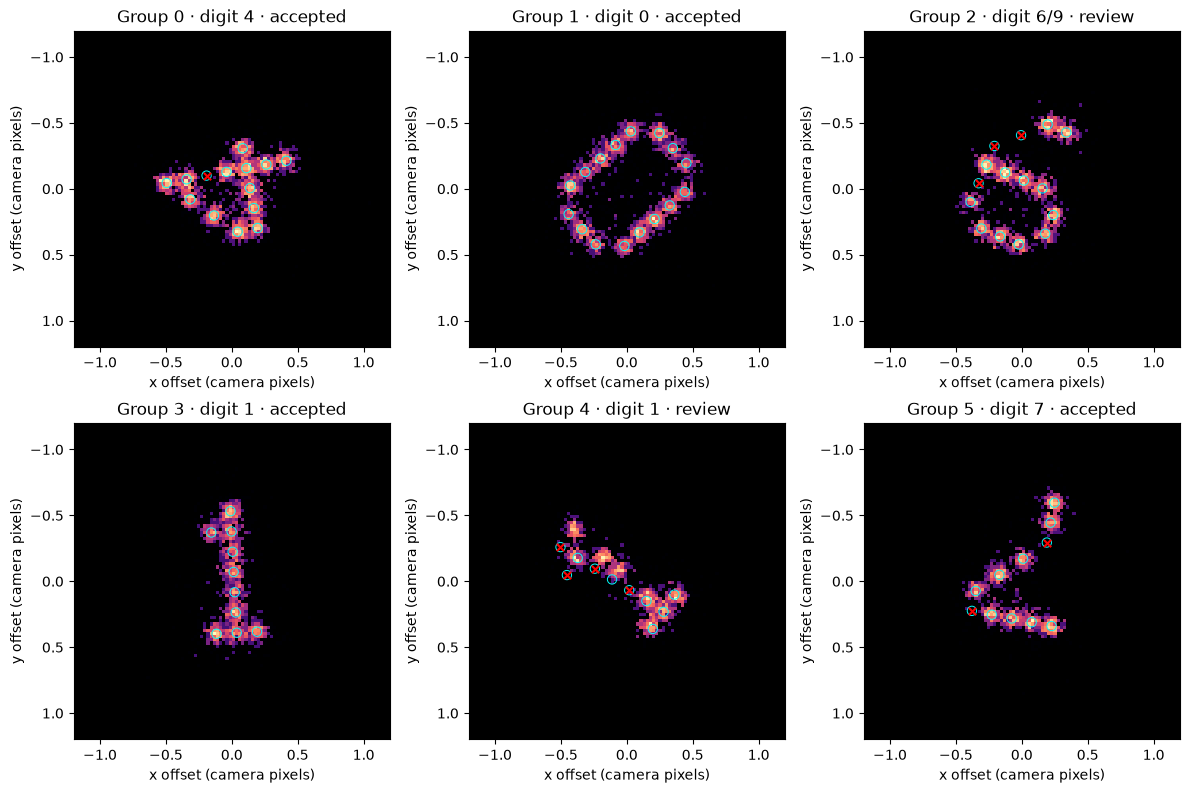

In [5]:
inspect_groups = list(groups[:6])  # Choose any fitted group IDs, for example [0, 2, 5].
columns = min(3, len(inspect_groups))
rows = int(np.ceil(len(inspect_groups)/columns))
fig, axes = plt.subplots(rows, columns, figsize=(4*columns, 4*rows), squeeze=False)
cmap = plt.colormaps["magma"].with_extremes(bad="black")
for group, ax in zip(inspect_groups, axes.flat):
    result = results[int(group)]
    row = result["summary"]
    center = particles.loc[group, ["x", "y"]].to_numpy(dtype=float)
    xy = locs.iloc[group_indices[group]][["x", "y"]].to_numpy()-center
    sites = result["grid_xy"]-center
    expected = patterns[result["template_index"]].ravel()
    missing = expected & ~result["observed"].ravel()
    ax.hist2d(*xy.T, bins=100, range=[[-radius, radius], [-radius, radius]],
              norm=LogNorm(), cmap=cmap)
    ax.scatter(*sites[expected].T, s=45, facecolors="none", edgecolors="cyan", linewidths=0.7)
    ax.scatter(*sites[missing].T, s=28, marker="x", c="red")
    status = "accepted" if row["accepted"] else "review"
    ax.set(title=f"Group {group} · digit {row['equivalent_digits']} · {status}",
           xlabel="x offset (camera pixels)", ylabel="y offset (camera pixels)", aspect="equal")
    ax.set_xlim(-radius, radius)
    ax.set_ylim(radius, -radius)
for ax in list(axes.flat)[len(inspect_groups):]:
    ax.set_visible(False)
fig.tight_layout()
plt.show()

## 5. Compare every design with a representative particle

One pair is shown for each distinguishable class: **0, 1, 2, 3, 4, 5, 6/9, 7 and 8**. Each pair shows the original design and the first accepted example, with fit metrics below. If none is accepted, a review example is shown with an orange title; the ambiguous 6/9 class has no uniquely accepted fit.

Both images share the same camera-pixel display window. Particles are aligned by their fitted poses; cyan outlines show intended sites and red crosses mark below-threshold evidence. The footer summarizes the run's acceptance, not accuracy.

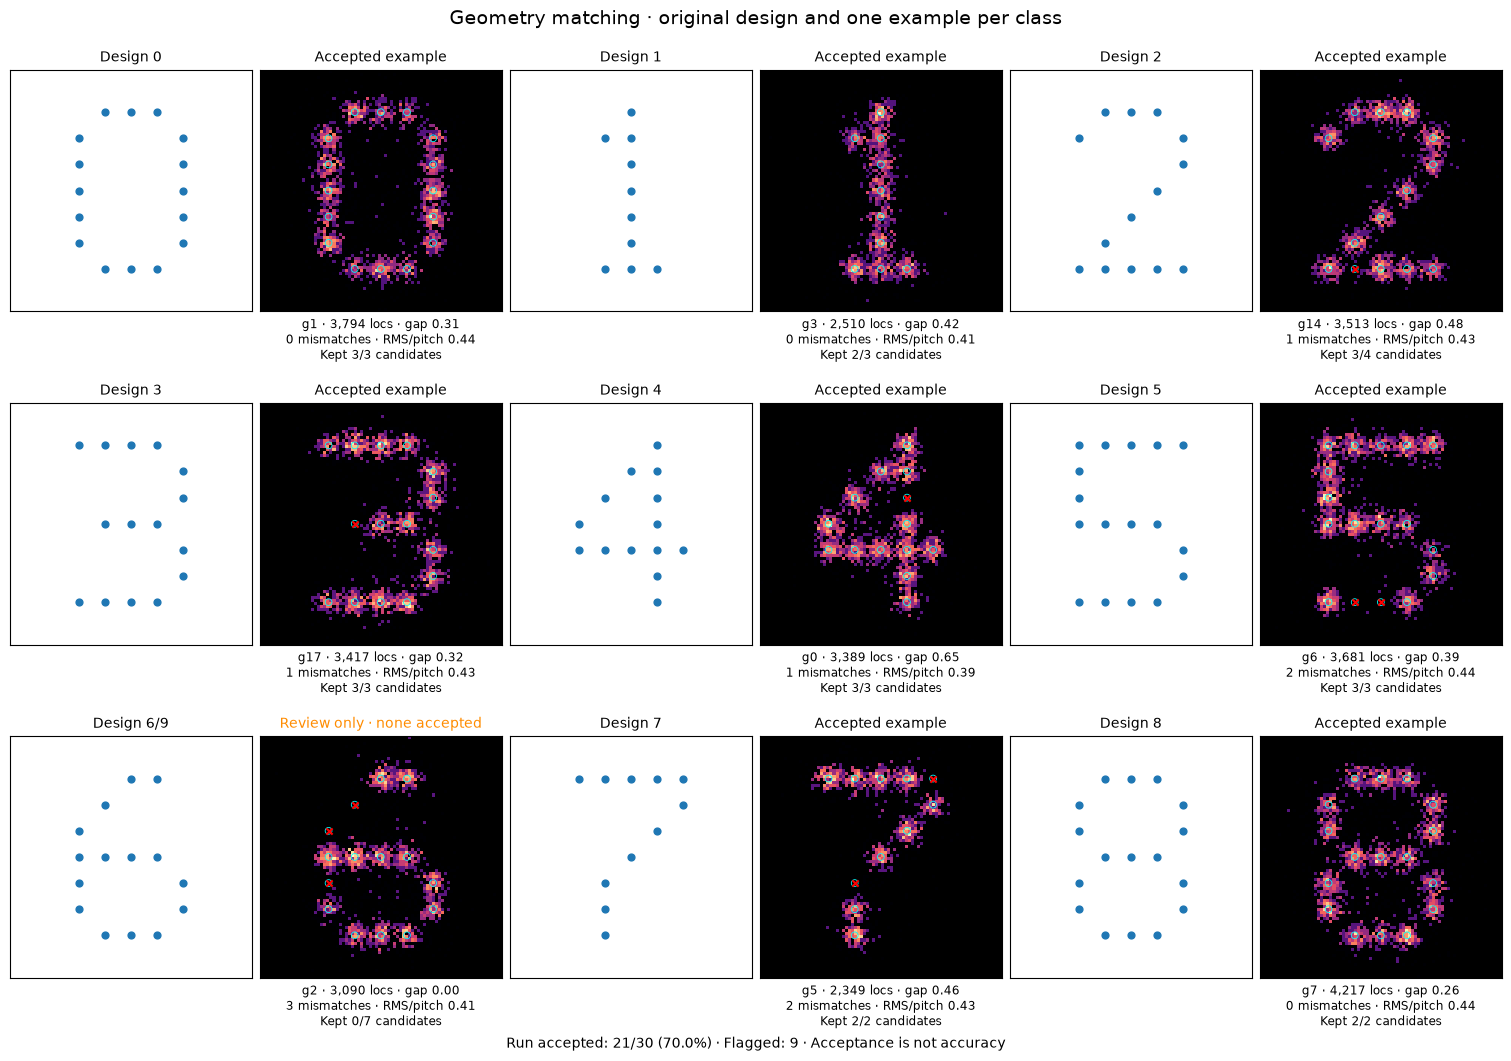

In [ ]:
from src.geometry_matching import rotation, equivalent_templates

comparison_classes = sorted({tuple(sorted(class_ids[equivalent_templates(patterns, grid, i)]))
                             for i in range(len(class_ids))})
columns = min(3, len(comparison_classes))
rows = int(np.ceil(len(comparison_classes) / columns))
view_radius = min(radius, np.abs(grid).max() + 0.25)
fig, axes = plt.subplots(rows, 2*columns, figsize=(5*columns, 3.5*rows),
                         squeeze=False, layout="constrained")
for index, members in enumerate(comparison_classes):
    design_ax, example_ax = axes[index//columns, 2*(index % columns):2*(index % columns)+2]
    name = "/".join(str(digit) for digit in members)
    choices = assignments.loc[assignments.best_digit.isin(members)]
    kept = choices.loc[choices.accepted]
    examples = kept if not kept.empty else choices
    template = int(np.flatnonzero(class_ids == members[0])[0])
    if examples.empty:
        example_ax.text(0.5, 0.5, "No example available", ha="center", transform=example_ax.transAxes)
        example_ax.set_title("No accepted example", color="darkorange")
    else:
        row = examples.iloc[0]  # First accepted example; otherwise a clearly flagged review example.
        group = int(row.group)
        result = results[group]
        template = result["template_index"]
        xy = locs.iloc[group_indices[group]][["x", "y"]].to_numpy()
        aligned = (xy - [row.center_x, row.center_y]) @ rotation(np.deg2rad(-row.angle_deg))
        reference = grid[patterns[template].ravel()]
        example_ax.hist2d(*aligned.T, bins=80, range=[[-view_radius, view_radius]]*2,
            norm=LogNorm(), cmap=plt.colormaps["magma"].with_extremes(bad="black"))
        example_ax.scatter(*reference.T, s=24, facecolors="none", edgecolors="cyan", linewidths=0.6)
        missing = patterns[template].ravel() & ~result["observed"].ravel()
        example_ax.scatter(*grid[missing].T, s=20, marker="x", color="red")
        example_ax.set_title("Accepted example" if row.accepted else "None accepted",
                             color="black" if row.accepted else "darkorange", fontsize=10)
        example_ax.set_xlabel(
            f"g{group} · {int(row.n_locs):,} locs · gap {row.score_gap:.2f}\n"
            f"{int(row.hamming)} mismatches · RMS/pitch {row.rms_pitch:.2f}\n"
            f"Kept {len(kept)}/{len(choices)} candidates", fontsize=8.5)
    design_ax.scatter(*grid[patterns[template].ravel()].T, s=24, color="tab:blue")
    design_ax.set_title(f"Design {name}", fontsize=10)
    for ax in (design_ax, example_ax):
        ax.set(xlim=(-view_radius, view_radius), ylim=(view_radius, -view_radius),
               aspect="equal", xticks=[], yticks=[])
for index in range(len(comparison_classes), rows*columns):
    for ax in axes[index//columns, 2*(index % columns):2*(index % columns)+2]:
        ax.set_visible(False)
fig.suptitle("Geometry matching · original design and one example per class", fontsize=14)
fig.supxlabel(
    f"Run accepted: {assignments.accepted.sum()}/{len(assignments)} ({assignments.accepted.mean():.1%}) · "
    f"Flagged: {(~assignments.accepted).sum()} · Acceptance is not accuracy", fontsize=10)
plt.show()


## 6. Save the matching results

Save the assignment table and each pattern's score under the picking folder. Preview and full results stay separate. Images remain inline; no settings file is exported. `group` still refers to the notebook 02 selection, and source localizations are unchanged.

In [7]:
output_dir = input_dir / run_id / scope
output_dir.mkdir(parents=True, exist_ok=True)
assignments.to_csv(output_dir / "particle_assignments.csv", index=False)
score_rows = [dict(group=group, digit=candidate["digit"], score=candidate["score"],
                   hamming=candidate["hamming"])
              for group, result in results.items() for candidate in result["matches"]]
pd.DataFrame(score_rows).to_csv(output_dir / "template_scores.csv", index=False)
print(f"Saved {output_dir.relative_to(project_dir)}")
assignments.reason.value_counts().rename("particles")

Saved data/derived/digits/full_01/picasso_addon/geometry_01/full


reason
accepted                                 21
ambiguous_class                           7
too_many_bit_mismatches                   1
not_converged;too_many_bit_mismatches     1
Name: particles, dtype: int64

## 7. Method, literature and parameter choices

**Method and literature:** [Dickinson et al. (2021)](https://doi.org/10.1038/s41467-021-22277-y) fit localization grids and compare site patterns in dNAM. [Wu et al. (LocMoFit, 2023)](https://doi.org/10.1038/s41592-022-01676-z) describe model-based fitting directly to SMLM coordinates. These motivate the [fitting implementation](../src/geometry_matching.py)

Each localization contributes a Gaussian with variance `mean(lpx², lpy²) + extra_sigma²`, plus a uniform background over the circular crop. The fit alternates site weights, rigid alignment and extra width (up to 0.08 camera pixels). It compares normalized signed site intensities against every template, allowing 180° orientation changes and small, nonwrapping grid shifts. Mirrors are not equivalent. Finite starts and cropped Gaussian tails are approximations; repeated detections do not give calibrated confidence.

**Parameter origins:** spacing and pixel size come from the saved simulation, currently **20 nm** and **130 nm/pixel**. The 25% occupancy rule follows the [authors’ dNAM implementation](https://github.com/BoiseState/NAM/blob/master/localization_preprocessing/dnam_mixed_origami_process.py); the numerical search and rejection settings below are adjustable starting choices for this dataset, not published performance guarantees.

| Parameters | Meaning and tuning |
|---|---|
| `max_fit_locs=2000`, `seed=7` | Reproducible fitting subsample. Increase the limit for more evidence at greater cost; residual checks use all valid detections. |
| `angle_step=10`, `n_starts=8` | Coarse spacing in degrees and number of refined starting poses. Smaller steps or more starts reduce missed alignments but take longer. |
| `max_iter=150` | Iterations per start. Increase for nonconverged fits. |
| `threshold_fraction=0.25`, `max_hamming=6` | Call a site occupied above 25% of the ten brightest sites' mean signal; allow up to six occupancy disagreements. Missing or dim sites affect both. |
| `min_gap=0.05` | Minimum score difference between candidate classes. Larger values require clearer separation; exactly equivalent designs remain ambiguous. |
| `max_background=0.35`, `max_rms_pitch=0.8` | Maximum fitted background fraction and nearest-grid residual divided by spacing. Lower values reject more fits. |

Acceptance counts measure selection yield, not accuracy. The 6/9 rotation ambiguity cannot be resolved by collecting more localizations from the same design. Known simulation labels can evaluate results afterward; they are not passed into matching.